# Clase asincrónica 6: Georreferenciación

**Nota**: Este notebook contiene el código utilizado para demostrar los temas de la clase 6.
Si lo ejecutás o modificás, recomendamos que hagas una copia ("_save as_" con otro nombre) para de esa manera evitar errores de `git` al hacer `pull`'s desde GitHub en el futuro.

## 1. GeoPandas

Para que este código se ejecute correctamente deberían instalar la versión 0.14.x de Geopandas, por ejemplo 0.14.4 que es la última (recientemente salió la 1.0 que deja obsoletas algunas de las funcionalidades que usamos aquí).
Podemos especificar la versión así `conda install -c conda-forge geopandas==0.14.4` o `pip install geopandas==0.14.4`.

In [37]:
import geopandas as gpd

In [38]:
gpd.__version__

'0.14.4'

Importamos un dataset del mundo:

In [39]:
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
mundo_gdf = gpd.read_file(url)

# Normalizar nombres de columnas (vienen en mayúsculas)
mundo_gdf.columns = mundo_gdf.columns.str.lower()

# Francia, Noruega, etc. vienen con iso_a3 = "-99"; usar adm0_a3 como respaldo
mundo_gdf["iso_a3"] = mundo_gdf["iso_a3"].where(mundo_gdf["iso_a3"] != "-99", mundo_gdf["adm0_a3"])

# En versiones nuevas la columna se llama gdp_md; en las viejas, gdp_md_est
gdp_col = "gdp_md_est" if "gdp_md_est" in mundo_gdf.columns else "gdp_md"

mundo_gdf = (
    mundo_gdf[["pop_est", "continent", "name", "iso_a3", gdp_col, "geometry"]]
    .rename(columns={gdp_col: "gdp_md_est"})
)

mundo_gdf.head()

,pop_est,continent,name,iso_a3,gdp_md_est,geometry
0,889953.0,Oceania,Fiji,FJI,5496,"MULTIPOLYGON (((180.00000 -16.06713, 180.00000..."
1,58005463.0,Africa,Tanzania,TZA,63177,"POLYGON ((33.90371 -0.95000, 34.07262 -1.05982..."
2,603253.0,Africa,W. Sahara,ESH,907,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,37589262.0,North America,Canada,CAN,1736425,"MULTIPOLYGON (((-122.84000 49.00000, -122.9742..."
4,328239523.0,North America,United States of America,USA,21433226,"MULTIPOLYGON (((-122.84000 49.00000, -120.0000..."


In [40]:
type(mundo_gdf)

geopandas.geodataframe.GeoDataFrame

In [41]:
mundo_gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [42]:
print(mundo_gdf.geometry[0])

MULTIPOLYGON (((180 -16.067133, 180 -16.555217, 179.364143 -16.801354, 178.725059 -17.012042, 178.596839 -16.63915, 179.096609 -16.433984, 179.413509 -16.379054, 180 -16.067133)), ((178.12557 -17.50481, 178.3736 -17.33992, 178.71806 -17.62846, 178.55271 -18.15059, 177.93266 -18.28799, 177.38146 -18.16432, 177.28504 -17.72465, 177.67087 -17.38114, 178.12557 -17.50481)), ((-179.79332 -16.020882, -179.917369 -16.501783, -180 -16.555217, -180 -16.067133, -179.79332 -16.020882)))


In [43]:
fiji = mundo_gdf.geometry[0]

In [44]:
fiji.area

1.639511559269503

In [45]:
type(fiji.centroid)

shapely.geometry.point.Point

In [46]:
gdf_mask = gpd.read_file(
    gpd.datasets.get_path("naturalearth_lowres")
)
gdf = gpd.read_file(
    gpd.datasets.get_path("naturalearth_cities"),
    mask=gdf_mask[gdf_mask.continent=="Africa"],
)


/tmp/ipykernel_5294/1832315912.py:2: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gpd.datasets.get_path("naturalearth_lowres")
/tmp/ipykernel_5294/1832315912.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_cities' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gpd.datasets.get_path("naturalearth_cities"),


In [47]:
import geopandas as gpd

gdf_mask = gpd.read_file(
    gpd.datasets.get_path("naturalearth_lowres")
)
gdf = gpd.read_file(
    gpd.datasets.get_path("naturalearth_cities"),
    mask=gdf_mask[gdf_mask.name=="Argentina"],
)

gdf

/tmp/ipykernel_5294/431896515.py:4: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gpd.datasets.get_path("naturalearth_lowres")
/tmp/ipykernel_5294/431896515.py:7: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_cities' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gpd.datasets.get_path("naturalearth_cities"),


,name,geometry
0,Buenos Aires,POINT (-58.43251 -34.61071)


In [48]:
gpd.__version__

'0.14.4'

In [49]:
gdf_mask = gpd.read_file(
    gpd.datasets.get_path("naturalearth_lowres")
)
gdf = gpd.read_file(
    gpd.datasets.get_path("naturalearth_cities"),
    mask=gdf_mask[gdf_mask.name=="Argentina"],
)
gdf

/tmp/ipykernel_5294/3378934746.py:2: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gpd.datasets.get_path("naturalearth_lowres")
/tmp/ipykernel_5294/3378934746.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_cities' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gpd.datasets.get_path("naturalearth_cities"),


,name,geometry
0,Buenos Aires,POINT (-58.43251 -34.61071)


### Bajamos un mapa de las provincias de Argentina

Pueden mirar la siguiente página del *Instituto Geográfico Nacional* (IGN): https://www.ign.gob.ar/NuestrasActividades/InformacionGeoespacial/CapasSIG

Para no hacer muy pesado el repo de GitHub, dejamos los siguientes archivos georreferenciados fuera del mismo, por lo que tienen que bajarlos ustedes mismos y copiarlos en el path correspondiente.

In [50]:
provincias_gdf = gpd.read_file(filename="provincia.shp")

In [51]:
provincias_gdf.columns

Index(['gid', 'entidad', 'objeto', 'fna', 'gna', 'nam', 'in1', 'fdc', 'sag',
       'geometry'],
      dtype='object')

In [52]:
provincias2_gdf = gpd.read_file(filename="provincia.json")

In [53]:
provincias2_gdf.shape

(24, 10)

In [54]:
bbox = [-90, -35, -60, -20]

In [56]:
provincias3_gdf = gpd.read_file(filename="provincia.json", bbox=bbox)

In [57]:
provincias3_gdf.geometry

,geometry
0,"MULTIPOLYGON (((-66.66179 -31.92054, -66.60454..."
1,"MULTIPOLYGON (((-58.88082 -28.06682, -58.88360..."
2,"MULTIPOLYGON (((-65.42299 -30.11960, -65.49056..."
3,"MULTIPOLYGON (((-66.09976 -26.22049, -66.10088..."
4,"MULTIPOLYGON (((-64.49532 -26.21937, -64.49723..."
5,"MULTIPOLYGON (((-58.37735 -26.87223, -58.37764..."
6,"MULTIPOLYGON (((-58.37735 -26.87223, -58.37935..."
7,"MULTIPOLYGON (((-67.31774 -32.38203, -67.31763..."
8,"MULTIPOLYGON (((-62.13060 -30.47993, -62.10369..."
9,"MULTIPOLYGON (((-59.72664 -33.60389, -59.72830..."


In [58]:
provincias3_gdf.to_file("provincias_subconjunto.geojson", driver='GeoJSON')

## Elaboración de mapas

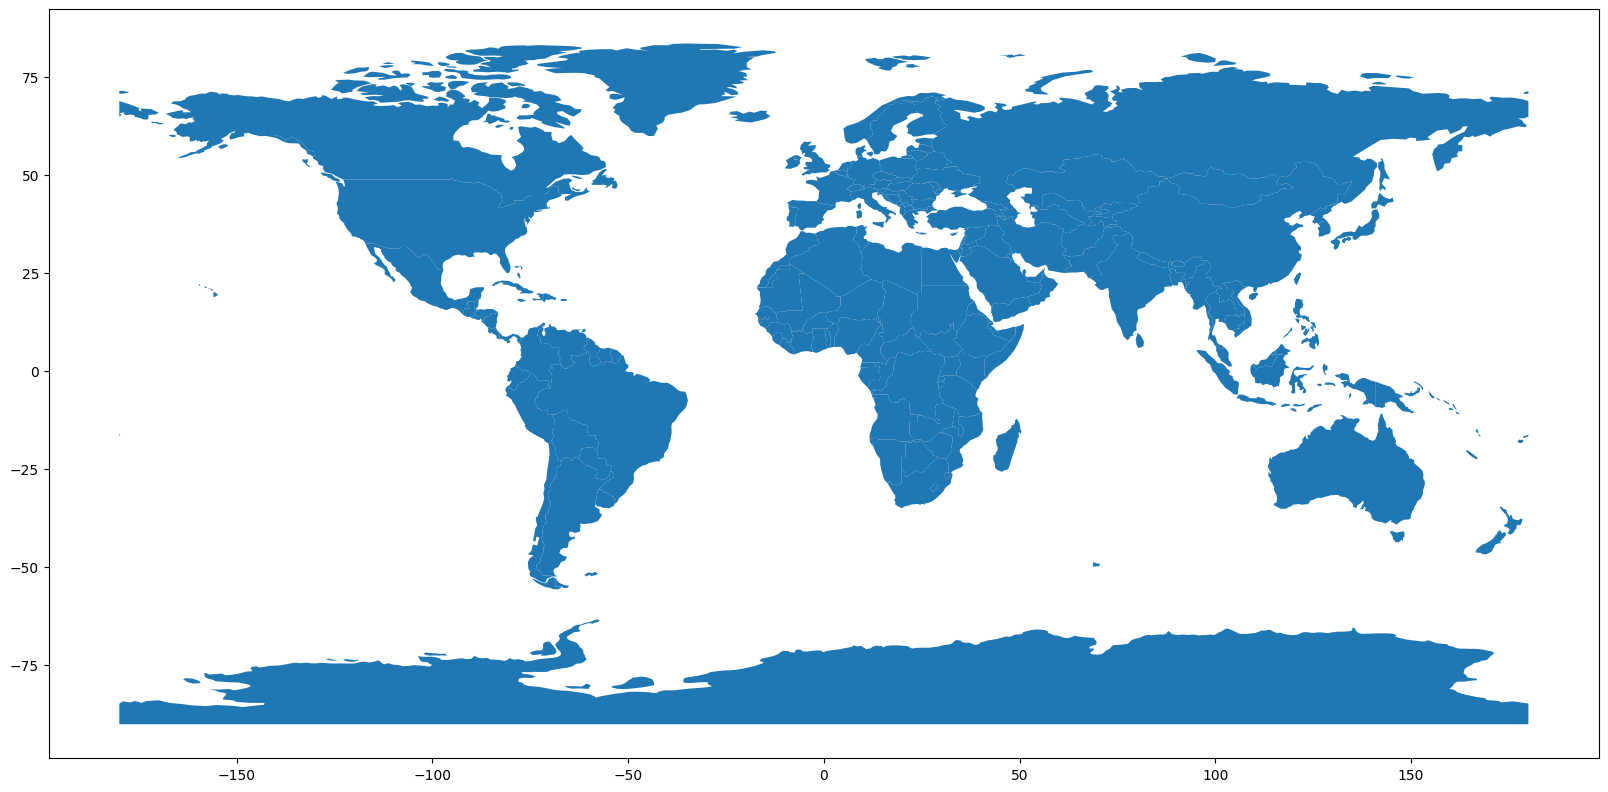

In [59]:
pp = mundo_gdf.plot(figsize=(20,10))

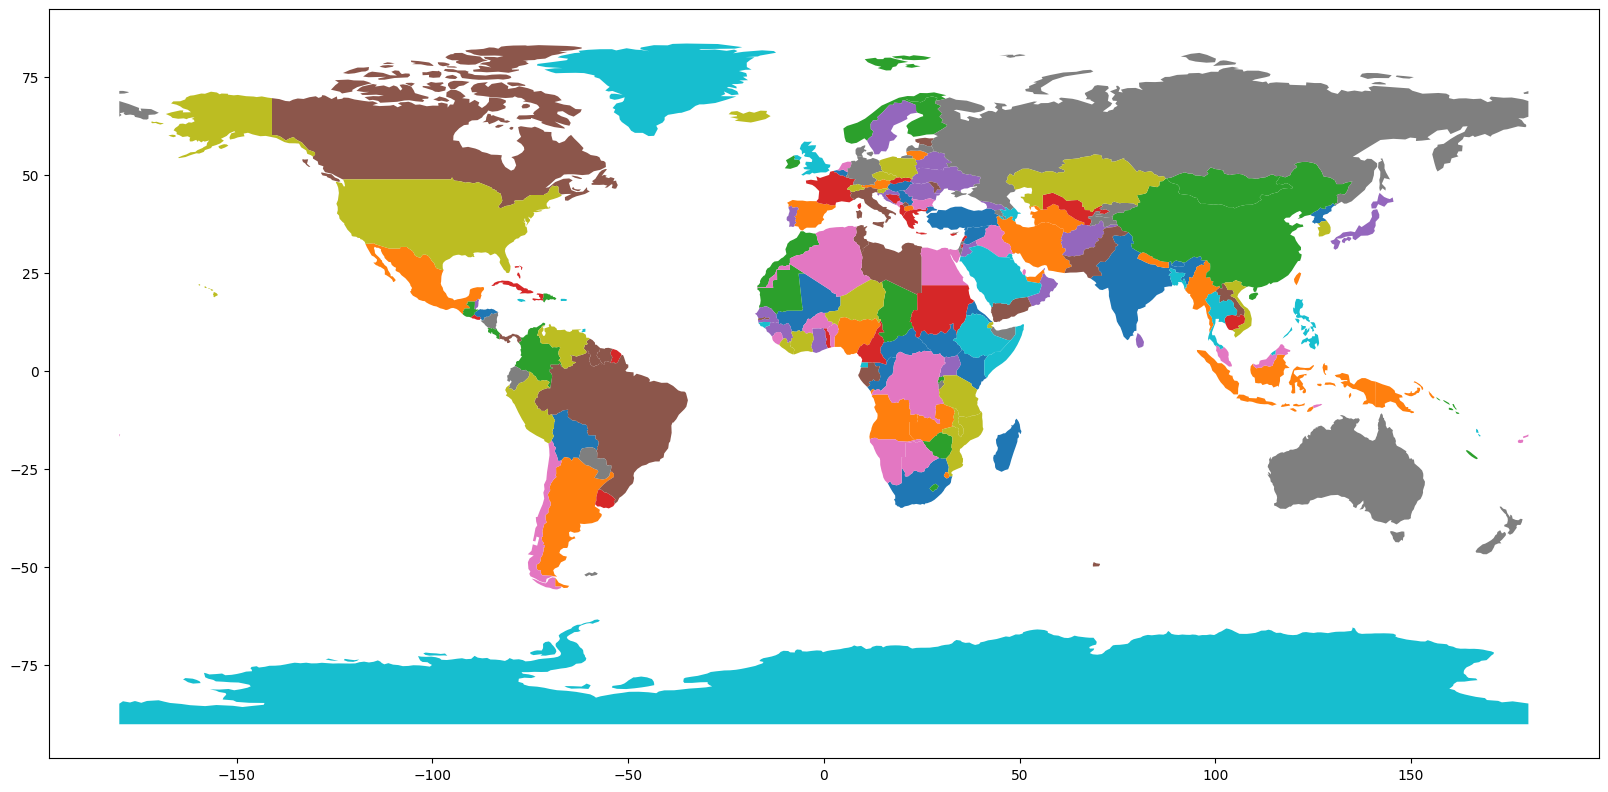

In [60]:
pp = mundo_gdf.sample(frac=1).reset_index(drop=True).plot(figsize=(20,10), cmap="tab10")

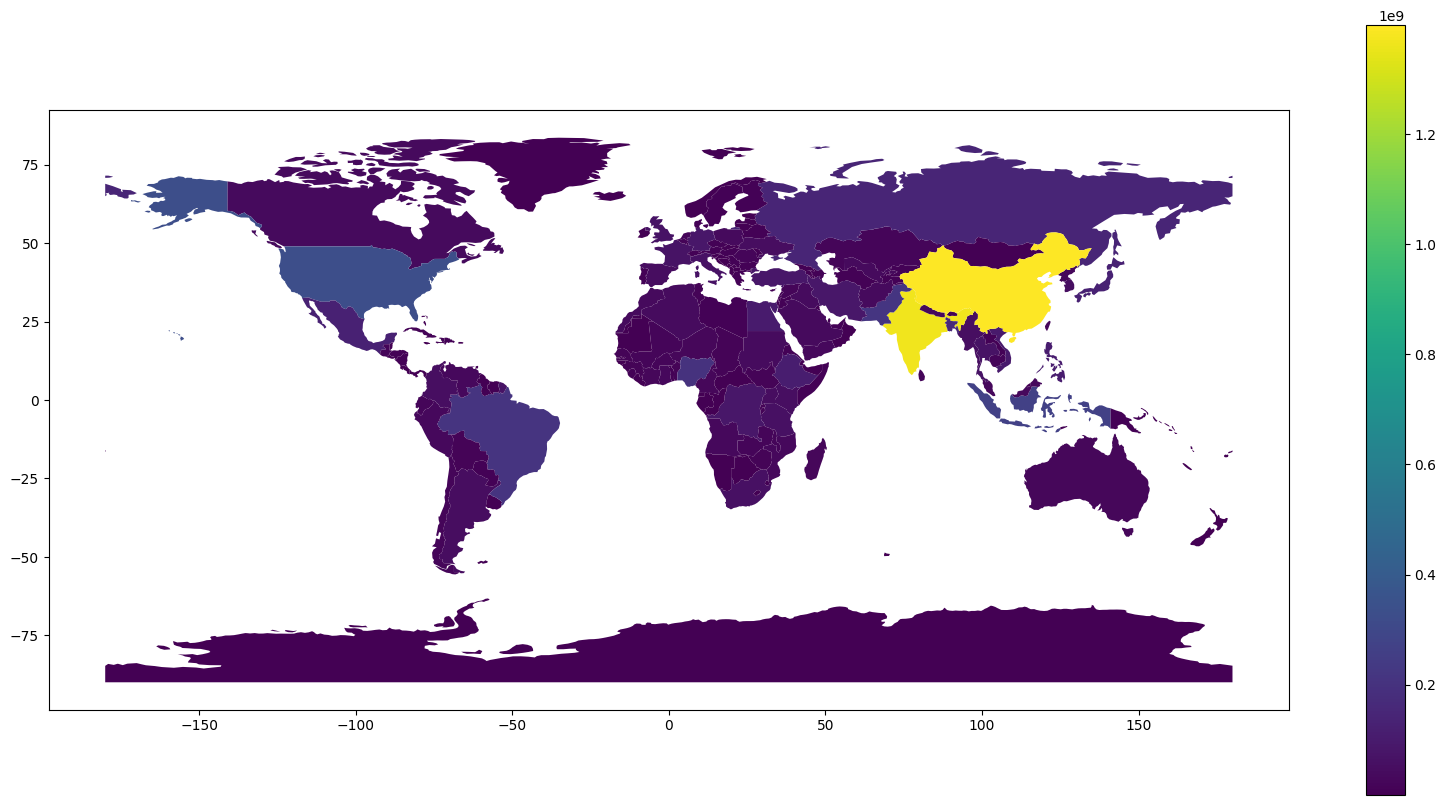

In [61]:
pp = mundo_gdf.plot(figsize=(20,10), column="pop_est", legend=True)

In [62]:
mundo_gdf["gdp_per_cap"] = mundo_gdf.gdp_md_est / mundo_gdf.pop_est * 1e6

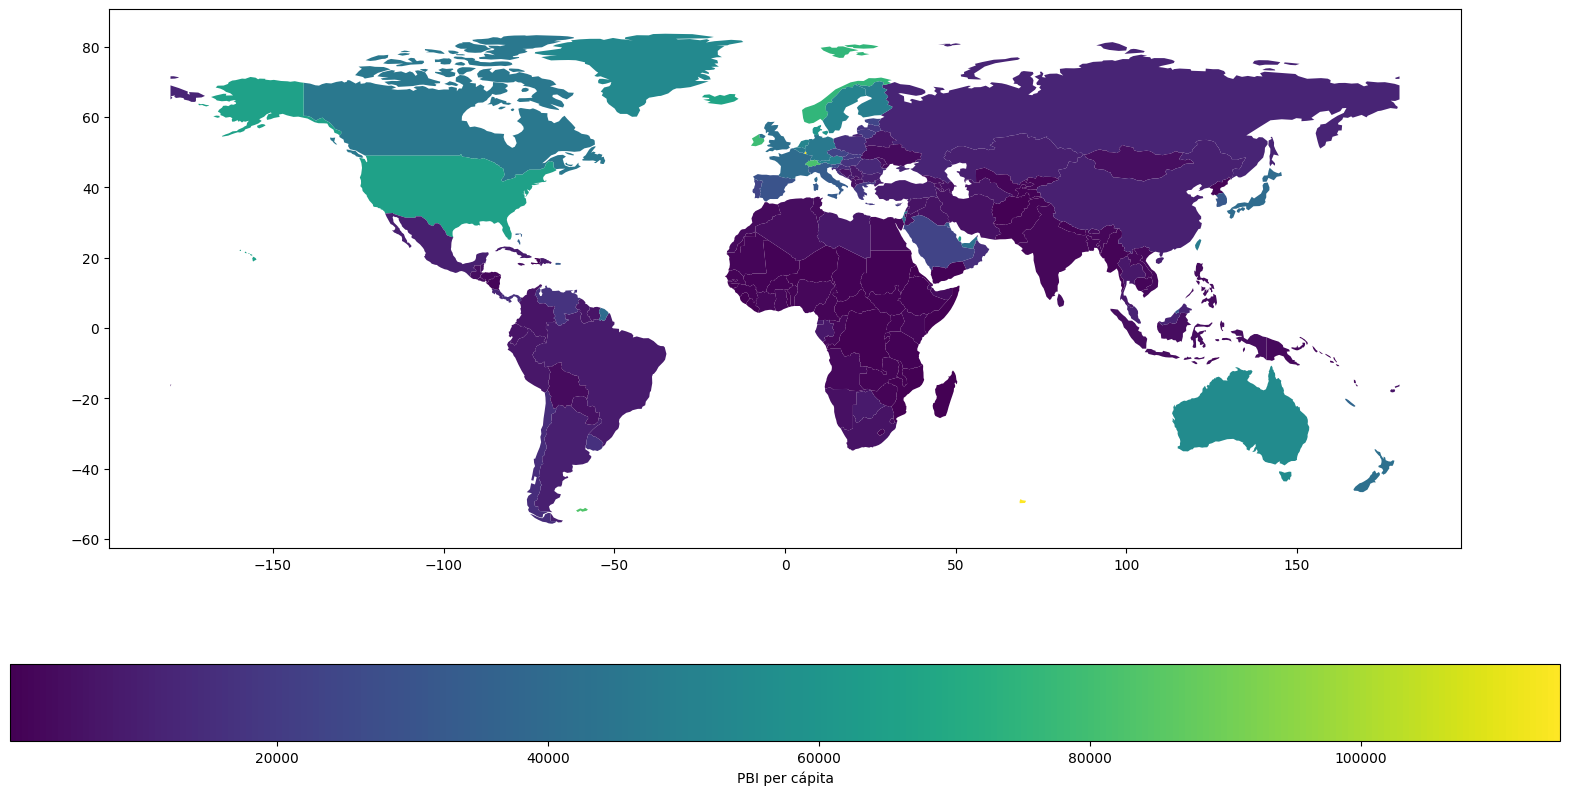

In [63]:
pp = mundo_gdf[mundo_gdf.continent != "Antarctica"].plot(
    figsize=(20,10),
    column="gdp_per_cap",
    legend=True,
    legend_kwds={'label': "PBI per cápita", 'orientation': "horizontal"}
)

### Valores faltantes

In [64]:
import numpy as np

In [65]:
mundo_vf_gdf = mundo_gdf.copy()

In [66]:
mundo_vf_gdf.loc[np.random.choice(mundo_vf_gdf.index, 50), "pop_est"] = np.nan

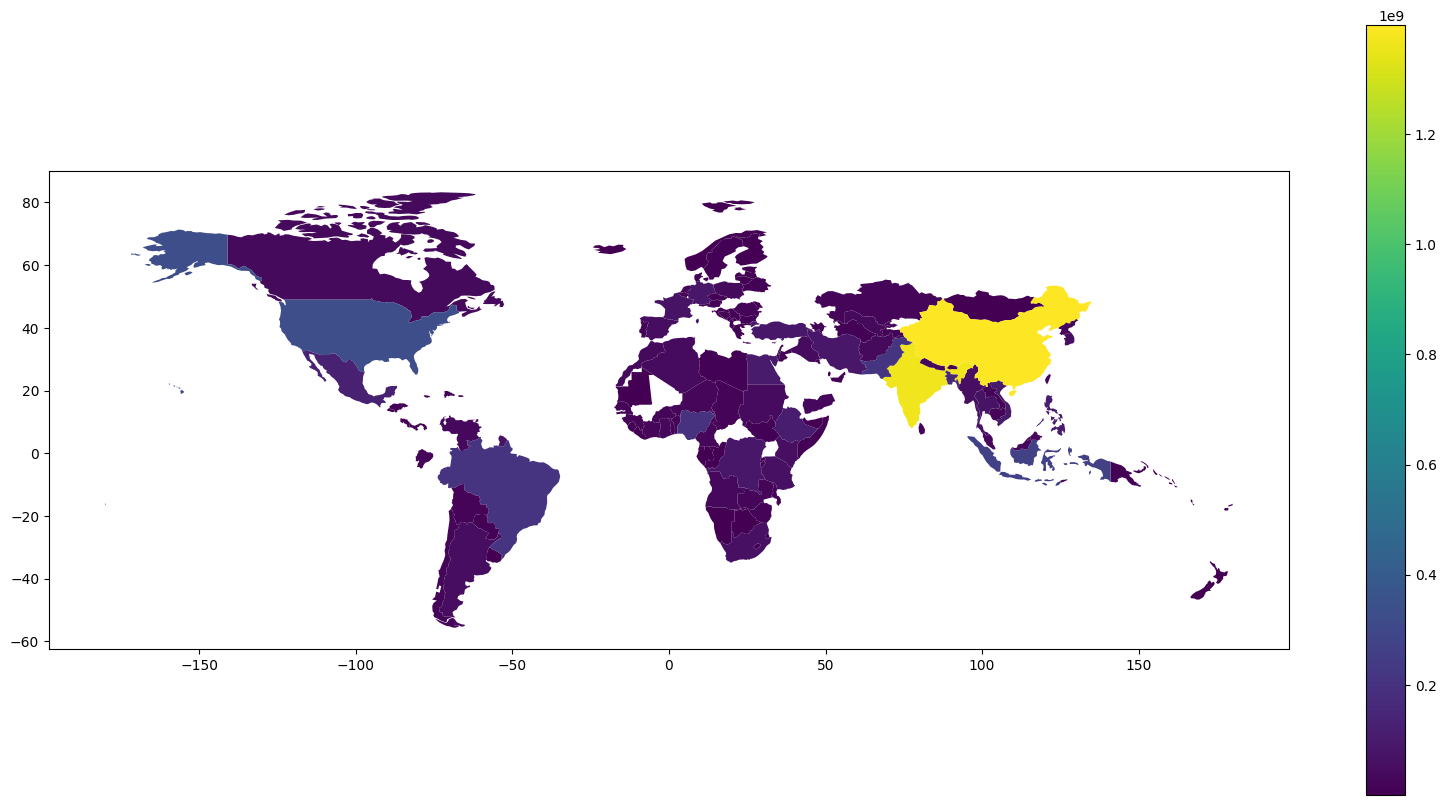

In [67]:
pp = mundo_vf_gdf.plot(figsize=(20,10), column="pop_est", legend=True)

In [ ]:
pp = mundo_vf_gdf.plot(figsize=(20,10), column="pop_est", legend=True, missing_kwds={'color': 'lightgrey'})

## Mapas interactivos

In [ ]:
# Si instalaron Geopandas con pip, probablemente les falten algunos paquetes para poder ejecutar esta celda correctamente, en particular folium y mapclassify, de ser así pueden instalarlos con pip o conda

provincias_gdf.explore()